In [ ]:
# Week 5 Forest Clustering

In [2]:
%pip install scikit-image


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 85.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 72.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-image]0m 4/5 [scikit-image]
Note: you may need to restart the kernel to use updated packages.


In [1]:
#Importing Libraries
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from skimage.io import imread
from skimage.color import rgb2gray
from skimage.transform import resize
from skimage.feature import hog

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

In [7]:
from pathlib import Path

home = Path.home()

for folder in [home / "Desktop", home / "ARU",
               home / "Master", home / "Machine learning in Imaging"]:
    if folder.exists():
        print(f"\nSearching in: {folder}")
        for path in folder.rglob("*"):
            if path.is_dir() and path.name in ["Aircraft", "Jellyfish"]:
                print("Found:", path)


Searching in: /Users/roy/Desktop
Found: /Users/roy/Desktop/ARU/Master/Machine learning in Imaging/Aircraft
Found: /Users/roy/Desktop/ARU/Master/Machine learning in Imaging/Jellyfish


In [2]:
from pathlib import Path

home = Path.home()

search_locations = [
    home / "Desktop",
    home / "ARU",
    home / "Master",
    home / "Machine learning in Imaging"
]

found_folders = {
    "Aircraft": [],
    "Jellyfish": []
}

for folder in search_locations:
    if folder.exists():
        print(f"\nSearching in: {folder}")

        for path in folder.rglob("*"):
            if path.is_dir() and path.name in found_folders:
                found_folders[path.name].append(path)
                print("Found:", path)

# Check that both classes were found
for class_name, paths in found_folders.items():
    print(f"\n{class_name} folders found: {len(paths)}")

    if len(paths) == 0:
        print(f"WARNING: Could not find the {class_name} folder.")


Searching in: /Users/roy/Desktop
Found: /Users/roy/Desktop/ARU/Master/Machine learning in Imaging/Aircraft
Found: /Users/roy/Desktop/ARU/Master/Machine learning in Imaging/Jellyfish

Aircraft folders found: 1

Jellyfish folders found: 1


In [4]:
# If multiple folders were found, change [0] to the correct index.
# For example, use [1] to select the second matching folder.

if not found_folders["Aircraft"]:
    raise FileNotFoundError(
        "Aircraft folder not found. Add its parent folder to search_locations."
    )

if not found_folders["Jellyfish"]:
    raise FileNotFoundError(
        "Jellyfish folder not found. Add its parent folder to search_locations."
    )

aircraft_path = found_folders["Aircraft"][0]
jellyfish_path = found_folders["Jellyfish"][0]

class_folders = {
    "Aircraft": aircraft_path,
    "Jellyfish": jellyfish_path
}

for class_name, class_dir in class_folders.items():
    print(f"{class_name}: {class_dir}")

Aircraft: /Users/roy/Desktop/ARU/Master/Machine learning in Imaging/Aircraft
Jellyfish: /Users/roy/Desktop/ARU/Master/Machine learning in Imaging/Jellyfish


In [5]:
# Image Loading and extracting HOG Feature
IMAGE_SIZE = (128, 128)

ALLOWED_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

CLASS_NAMES = ["Aircraft", "Jellyfish"]

X_features = []
y_labels = []
loaded_paths = []

for class_name in CLASS_NAMES:
    class_dir = class_folders[class_name]

    if not class_dir.exists():
        raise FileNotFoundError(
            f"Could not find the folder: {class_dir}"
        )

    image_paths = sorted([
        p for p in class_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in ALLOWED_EXTENSIONS
    ])

    print(f"{class_name}: found {len(image_paths)} image files")

    for image_path in image_paths:
        try:
            image = imread(image_path)

            # Convert RGB or RGBA images to grayscale.
            # Grayscale images are kept as they are.
            if image.ndim == 3:
                image = image[:, :, :3]
                image = rgb2gray(image)

            elif image.ndim != 2:
                raise ValueError(
                    f"Unsupported image dimensions: {image.shape}"
                )

            # Resize all images to the same dimensions.
            image = resize(
                image,
                IMAGE_SIZE,
                anti_aliasing=True,
                preserve_range=True
            ).astype(np.float32)

            # Extract Histogram of Oriented Gradients (HOG).
            features = hog(
                image,
                orientations=9,
                pixels_per_cell=(8, 8),
                cells_per_block=(2, 2),
                block_norm="L2-Hys"
            )

            X_features.append(features)
            y_labels.append(class_name)
            loaded_paths.append(str(image_path))

        except Exception as error:
            print(f"Skipping {image_path}: {error}")

X = np.asarray(X_features)
y = np.asarray(y_labels)

print("\nFeature matrix shape:", X.shape)
print("Labels shape:", y.shape)

print(
    "Loaded images per class:",
    {
        name: int(np.sum(y == name))
        for name in CLASS_NAMES
    }
)

if len(X) == 0:
    raise ValueError(
        "No images were loaded. Check your folder paths and image formats."
    )

if len(np.unique(y)) < 2:
    raise ValueError(
        "At least two classes with readable images are needed."
    )

if min(np.sum(y == name) for name in CLASS_NAMES) < 2:
    raise ValueError(
        "Each class needs at least two readable images "
        "for a stratified train/test split."
    )

Aircraft: found 732 image files
Jellyfish: found 1127 image files

Feature matrix shape: (1859, 8100)
Labels shape: (1859,)
Loaded images per class: {'Aircraft': 732, 'Jellyfish': 1127}


In [6]:
# Training Set and testing set
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print(
    "Training class counts:",
    {
        name: int(np.sum(y_train == name))
        for name in CLASS_NAMES
    }
)

print(
    "Test class counts:",
    {
        name: int(np.sum(y_test == name))
        for name in CLASS_NAMES
    }
)

Training samples: 1394
Test samples: 465
Training class counts: {'Aircraft': 549, 'Jellyfish': 845}
Test class counts: {'Aircraft': 183, 'Jellyfish': 282}


In [7]:
# Baseline Random Forest
baseline_model = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_features="sqrt",
    random_state=42,
    n_jobs=-1,
    oob_score=True
)

baseline_model.fit(X_train, y_train)

baseline_train_pred = baseline_model.predict(X_train)
baseline_test_pred = baseline_model.predict(X_test)

baseline_train_accuracy = accuracy_score(
    y_train, baseline_train_pred
)

baseline_test_accuracy = accuracy_score(
    y_test, baseline_test_pred
)

print(f"Baseline training accuracy: {baseline_train_accuracy:.3f}")
print(f"Baseline test accuracy:     {baseline_test_accuracy:.3f}")
print(f"Baseline OOB score:         {baseline_model.oob_score_:.3f}")

print("\nBaseline test classification report:")
print(
    classification_report(
        y_test,
        baseline_test_pred,
        labels=CLASS_NAMES,
        zero_division=0
    )
)

Baseline training accuracy: 1.000
Baseline test accuracy:     0.766
Baseline OOB score:         0.796

Baseline test classification report:
              precision    recall  f1-score   support

    Aircraft       0.76      0.59      0.66       183
   Jellyfish       0.77      0.88      0.82       282

    accuracy                           0.77       465
   macro avg       0.76      0.73      0.74       465
weighted avg       0.76      0.77      0.76       465



In [8]:
# Random Forest hyperparameters
min_class_count = int(
    min(np.sum(y_train == label) for label in np.unique(y_train))
)

if min_class_count < 2:
    raise ValueError(
        "There are too few training images in at least one class "
        "for 2-fold cross-validation."
    )

n_splits = min(5, min_class_count)

cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.5]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        criterion="gini",
        random_state=42,
        n_jobs=-1
    ),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print(
    "Best cross-validation macro-F1:",
    round(grid_search.best_score_, 3)
)

print("Best hyperparameters:", grid_search.best_params_)

Best cross-validation macro-F1: 0.785
Best hyperparameters: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 2, 'n_estimators': 200}


In [10]:
from sklearn.metrics import precision_score, recall_score, f1_score

In [11]:
# Tuned Model
best_model = grid_search.best_estimator_

tuned_train_pred = best_model.predict(X_train)
tuned_test_pred = best_model.predict(X_test)

tuned_train_accuracy = accuracy_score(
    y_train, tuned_train_pred
)

tuned_test_accuracy = accuracy_score(
    y_test, tuned_test_pred
)

tuned_precision = precision_score(
    y_test, tuned_test_pred,
    average="macro",
    zero_division=0
)

tuned_recall = recall_score(
    y_test, tuned_test_pred,
    average="macro",
    zero_division=0 
)

tuned_f1 = f1_score(
    y_test, tuned_test_pred,
    average="macro",
    zero_division=0
)

print(f"Tuned training accuracy: {tuned_train_accuracy:.3f}")
print(f"Tuned test accuracy:     {tuned_test_accuracy:.3f}")
print(f"Test macro precision:    {tuned_precision:.3f}")
print(f"Test macro recall:       {tuned_recall:.3f}")
print(f"Test macro-F1:           {tuned_f1:.3f}")

print("\nTuned model classification report:")
print(
    classification_report(
        y_test,
        tuned_test_pred,
        labels=CLASS_NAMES,
        zero_division=0
    )
)

Tuned training accuracy: 1.000
Tuned test accuracy:     0.802
Test macro precision:    0.811
Test macro recall:       0.771
Test macro-F1:           0.781

Tuned model classification report:
              precision    recall  f1-score   support

    Aircraft       0.83      0.62      0.71       183
   Jellyfish       0.79      0.92      0.85       282

    accuracy                           0.80       465
   macro avg       0.81      0.77      0.78       465
weighted avg       0.81      0.80      0.80       465



In [12]:
# Comparing Baseline model and Tuned model
baseline_f1 = f1_score(
    y_test,
    baseline_test_pred,
    average="macro",
    zero_division=0
)

comparison = {
    "Baseline": {
        "Training Accuracy": baseline_train_accuracy,
        "Test Accuracy": baseline_test_accuracy,
        "Test Macro-F1": baseline_f1
    },
    "Tuned": {
        "Training Accuracy": tuned_train_accuracy,
        "Test Accuracy": tuned_test_accuracy,
        "Test Macro-F1": tuned_f1
    }
}

print(f"{'Model':<12} {'Train Acc.':>12} {'Test Acc.':>12} {'Macro-F1':>12}")
print("-" * 50)

for model_name, scores in comparison.items():
    print(
        f"{model_name:<12}"
        f"{scores['Training Accuracy']:>12.3f}"
        f"{scores['Test Accuracy']:>12.3f}"
        f"{scores['Test Macro-F1']:>12.3f}"
    )

if tuned_f1 > baseline_f1:
    print("\nThe tuned model has the higher test macro-F1 score.")
elif baseline_f1 > tuned_f1:
    print("\nThe baseline model has the higher test macro-F1 score.")
else:
    print("\nBoth models have the same test macro-F1 score.")

Model          Train Acc.    Test Acc.     Macro-F1
--------------------------------------------------
Baseline           1.000       0.766       0.742
Tuned              1.000       0.802       0.781

The tuned model has the higher test macro-F1 score.


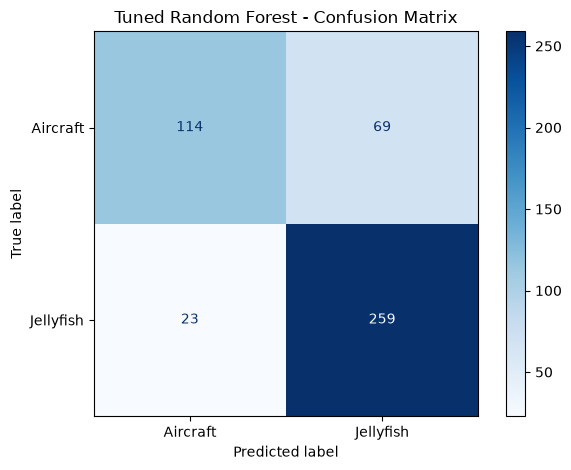

In [13]:
# Confusion_Matrix
cm = confusion_matrix(
    y_test,
    tuned_test_pred,
    labels=CLASS_NAMES
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Tuned Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

In [14]:
# Checking for possible overfitting
accuracy_gap = tuned_train_accuracy - tuned_test_accuracy

print(f"Training accuracy: {tuned_train_accuracy:.3f}")
print(f"Testing accuracy:  {tuned_test_accuracy:.3f}")
print(f"Accuracy gap:      {accuracy_gap:.3f}")

if accuracy_gap > 0.10:
    print(
        "\nThe model may be overfitting because its training accuracy "
        "is noticeably higher than its test accuracy."
    )
elif tuned_train_accuracy < 0.70 and tuned_test_accuracy < 0.70:
    print(
        "\nThe model may be underfitting, as both training and test "
        "accuracy are relatively low."
    )
else:
    print(
        "\nThere is no strong indication of underfitting or overfitting "
        "from this simple accuracy comparison. Check the class metrics too."
    )

Training accuracy: 1.000
Testing accuracy:  0.802
Accuracy gap:      0.198

The model may be overfitting because its training accuracy is noticeably higher than its test accuracy.


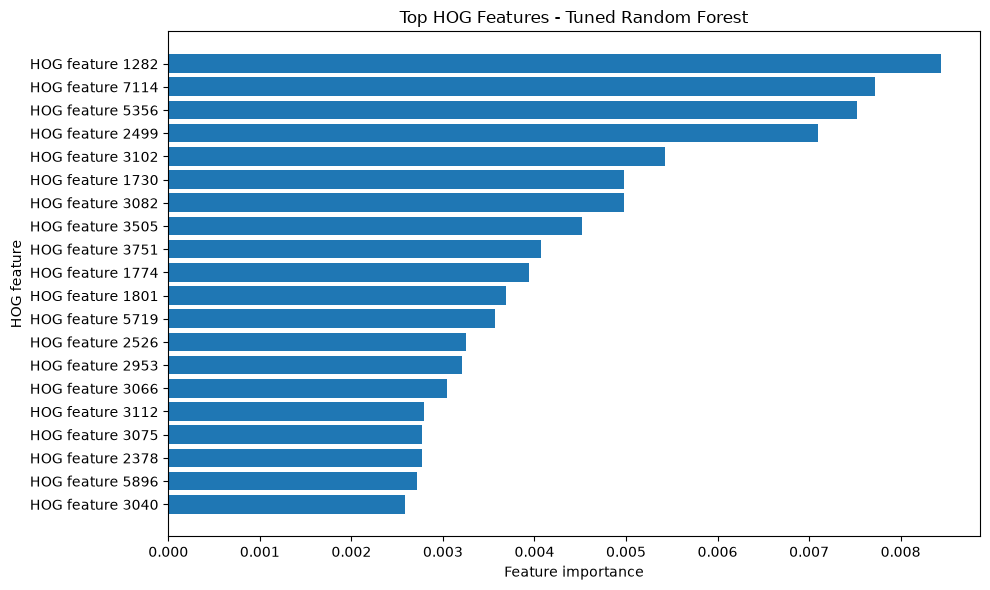

In [15]:
# Most Important HOG Featre
importances = best_model.feature_importances_

top_n = min(20, len(importances))
top_indices = np.argsort(importances)[-top_n:]

plt.figure(figsize=(10, 6))
plt.barh(
    range(top_n),
    importances[top_indices]
)
plt.yticks(
    range(top_n),
    [f"HOG feature {i}" for i in top_indices]
)
plt.xlabel("Feature importance")
plt.ylabel("HOG feature")
plt.title("Top HOG Features - Tuned Random Forest")
plt.tight_layout()
plt.show()